# 02 - Modelado Predictivo y Evaluación de Clasificación

**Asignatura:** Programación Avanzada en Ciencia de Datos  
**Problema:** Tipificación y Segmentación de Propiedades en CABA (Gama Alta vs. Estándar)  

Este notebook documenta el proceso experimental conforme a la consigna oficial:
1. **Preprocesamiento:** Pipeline con `ColumnTransformer` (imputación, escalado estándar y One-Hot Encoding).
2. **Modelos Evaluados:**
   - **Baseline Ingenuo (`DummyClassifier`):** Control experimental que predice la moda (clase mayoritaria).
   - **Baseline Lineal (`LogisticRegression`):** Clasificador paramétrico rápido con regularización L2.
   - **Ensamble no Lineal (`RandomForestClassifier`):** Modelo robusto basado en múltiples árboles de decisión.
3. **Optimización:** Búsqueda de hiperparámetros con `GridSearchCV` y validación cruzada estratificada.
4. **Evaluación:** Accuracy, Precision, Recall, F1-Score y Matriz de Confusión.
5. **Persistencia:** Almacenamiento del dataset limpio en SQLite y de resultados/parámetros en MongoDB.

In [1]:
import sys
from pathlib import Path

# Añadir directorio raíz al path para importar módulos de src
ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from config import YEARS, BASE_DIR, SQLITE_DB_PATH, SQLITE_TABLE_CLEAN, MONGO_URI, MONGO_DB_NAME
from src.data_loader import build_unified_dataset
from src.cleaning import clean_and_prepare_dataset
from src.features import build_preprocessor, split_features_and_target
from src.models import (
    create_dummy_classifier_pipeline,
    create_logistic_regression_pipeline,
    create_random_forest_pipeline,
    optimize_with_gridsearch,
    compare_models,
    save_model,
)
from src.evaluation import evaluate_classification, plot_and_save_confusion_matrix
from src.db_sql import save_clean_dataset
from src.db_mongo import save_model_results_mongo, save_model_parameters_mongo
from src.logger_setup import get_logger

logger = get_logger("02_modelado_notebook")
print("Entorno inicializado correctamente.")

Entorno inicializado correctamente.


## 1. Carga, Limpieza y Binarización del Target

In [2]:
# Cargar datos crudos unificados de los 16 años
df_raw = build_unified_dataset(YEARS)

# Ejecutar limpieza, filtrado de outliers y target ES_GAMA_ALTA
df_clean = clean_and_prepare_dataset(df_raw, quantile_threshold=0.75)

# Persistir exclusivamente el dataset limpio en SQLite (inmuebles.db)
save_clean_dataset(df_clean, SQLITE_DB_PATH, SQLITE_TABLE_CLEAN)
df_clean.head()

2026-11-10 09:24:51,698 | INFO     | src.data_loader | [2001] archivo encontrado: departamentos-en-venta-2001.csv
2026-11-10 09:24:51,823 | INFO     | src.data_loader | [2001] columnas ausentes (se rellenan con NaN): ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']
2026-11-10 09:24:51,825 | WARNING  | src.data_loader | [2001] 12911 filas con LAT/LON invertidas, se corrigen
2026-11-10 09:24:51,827 | INFO     | src.data_loader | [2001] estandarizado: (12911, 17) -> (12911, 22)
2026-11-10 09:24:51,828 | INFO     | src.data_loader | [2002] archivo encontrado: departamentos-en-venta-2002.csv
2026-11-10 09:24:51,858 | INFO     | src.data_loader | [2002] columnas ausentes (se rellenan con NaN): ['M2_CUBIERTOS', 'DORMITORIO', 'PISO', 'DIRECCION_NORMALIZADA']
2026-11-10 09:24:51,861 | INFO     | src.data_loader | [2002] estandarizado: (7363, 17) -> (7363, 22)
2026-11-10 09:24:51,862 | INFO     | src.data_loader | [2003] archivo encontrado: departamentos-en-venta-2003.csv
2026-11-

,AÑO,CALLE,NUMERO,M2,M2_CUBIERTOS,DOLARES,U_S_M2,AMBIENTES,DORMITORIO,PISO,...,COCHERA,BAÑOS,LAVADERO,TERRAZA,BARRIO,COMUNA,DIRECCION_NORMALIZADA,LAT,LON,ES_GAMA_ALTA
0,2001,11 DE SEPTIEMBRE DE 1888,882.0,105.0,NaN,173000.0,1647.6,NaN,NaN,NaN,...,1,2.0,0,0,PALERMO,14,NaN,-34.569951,-58.440246,1
1,2001,11 DE SEPTIEMBRE DE 1888,1050.0,180.0,NaN,169000.0,938.9,NaN,NaN,NaN,...,1,2.0,0,0,PALERMO,14,NaN,-34.568205,-58.442481,0
2,2001,11 DE SEPTIEMBRE DE 1888,1144.0,165.0,NaN,185000.0,1121.2,NaN,NaN,NaN,...,1,2.0,0,0,PALERMO,14,NaN,-34.567569,-58.443303,1
3,2001,11 DE SEPTIEMBRE DE 1888,1846.0,202.0,NaN,198000.0,980.2,NaN,NaN,NaN,...,1,2.0,0,0,BELGRANO,13,NaN,-34.561004,-58.449033,0
4,2001,11 DE SEPTIEMBRE DE 1888,2130.0,63.0,NaN,50000.0,793.7,NaN,NaN,NaN,...,0,0.0,0,0,BELGRANO,13,NaN,-34.558023,-58.451617,0


## 2. Partición de Datos (Train / Test Split)

In [3]:
X, y = split_features_and_target(df_clean, target_column="ES_GAMA_ALTA")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensiones entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Dimensiones prueba: X_test={X_test.shape}, y_test={y_test.shape}")

2026-11-10 09:24:59,163 | INFO     | src.features | Separación X / y completada: X=(176377, 10), y=(176377,)


Dimensiones entrenamiento: X_train=(141101, 10), y_train=(141101,)
Dimensiones prueba: X_test=(35276, 10), y_test=(35276,)


## 3. Preprocesamiento de Características (ColumnTransformer)

Construcción del transformador unificado:
- **Numéricas:** Imputación por mediana y estandarización (`StandardScaler`).
- **Categóricas:** Imputación por moda y codificación One-Hot (`OneHotEncoder`).

In [4]:
preprocessor = build_preprocessor()
print("ColumnTransformer configurado exitosamente.")

2026-11-10 09:25:07,847 | INFO     | src.features | Construyendo preprocesador: 8 variables numéricas, 2 categóricas.


ColumnTransformer configurado exitosamente.


## 4. Modelo 0: Baseline Ingenuo (DummyClassifier)

El clasificador trivial predice siempre la clase mayoritaria (0 = Estándar).  
Sirve como **control experimental**: demuestra que en un dataset desbalanceado se puede obtener ~75% de Accuracy pero con un **Recall y F1-Score de 0.00%** para la clase Gama Alta.

In [5]:
# Entrenar y evaluar DummyClassifier (estrategia clase más frecuente)
pipe_dummy = create_dummy_classifier_pipeline(preprocessor, strategy="most_frequent")
pipe_dummy.fit(X_train, y_train)

y_pred_dummy = pipe_dummy.predict(X_test)
metrics_dummy = evaluate_classification(y_test, y_pred_dummy)
print("Métricas DummyClassifier (Baseline Ingenuo):", {k: v for k, v in metrics_dummy.items() if k not in ["confusion_matrix", "classification_report"]})

2026-11-10 09:25:11,316 | INFO     | src.models | Pipeline de DummyClassifier (strategy='most_frequent') creado.
2026-11-10 09:25:11,515 | INFO     | src.evaluation | Calculando métricas de clasificación sobre 35276 muestras...
2026-11-10 09:25:11,542 | INFO     | src.evaluation | Métricas calculadas: Accuracy=0.7493 | Precision=0.5614 | Recall=0.7493 | F1=0.6419 | ROC-AUC=N/A


Métricas DummyClassifier (Baseline Ingenuo): {'accuracy': 0.749291302868806, 'precision': 0.5614374565548328, 'recall': 0.749291302868806, 'f1_score': 0.6419027587161561, 'f1_macro': 0.42833992351072797, 'roc_auc': None}


## 5. Modelo 1: Regresión Logística (Baseline Lineal)

In [6]:
# Modelo 1: Regresión Logística
pipe_lr = create_logistic_regression_pipeline(preprocessor)
pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)
metrics_lr = evaluate_classification(y_test, y_pred_lr)
print("Métricas Regresión Logística:", {k: v for k, v in metrics_lr.items() if k not in ["confusion_matrix", "classification_report"]})

2026-11-10 09:25:21,208 | INFO     | src.models | Pipeline de Regresión Logística creado.
2026-11-10 09:25:22,384 | INFO     | src.evaluation | Calculando métricas de clasificación sobre 35276 muestras...
2026-11-10 09:25:22,409 | INFO     | src.evaluation | Métricas calculadas: Accuracy=0.7603 | Precision=0.8118 | Recall=0.7603 | F1=0.7736 | ROC-AUC=N/A


Métricas Regresión Logística: {'accuracy': 0.7602902823449371, 'precision': 0.811760702931426, 'recall': 0.7602902823449371, 'f1_score': 0.7735664674607441, 'f1_macro': 0.7225390321860905, 'roc_auc': None}


## 6. Modelo 2: Random Forest con GridSearchCV


In [7]:
pipe_rf = create_random_forest_pipeline(preprocessor)

param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [10, 20],
}

# Subconjunto estratificado para optimización rápida
sample_idx = X_train.sample(n=min(30000, len(X_train)), random_state=42).index
grid_search = optimize_with_gridsearch(
    pipe_rf, param_grid, X_train.loc[sample_idx], y_train.loc[sample_idx], cv_splits=3
)

# Reentrenar el mejor pipeline con todo el conjunto de entrenamiento
best_rf = grid_search.best_estimator_
best_rf.fit(X_train, y_train)

2026-11-10 09:25:26,502 | INFO     | src.models | Pipeline de Random Forest creado.
2026-11-10 09:25:26,519 | INFO     | src.models | Iniciando GridSearchCV (2 combinaciones, 3-fold cross-validation, métrica='f1_weighted')...


Fitting 3 folds for each of 4 candidates, totalling 12 fits


2026-11-10 09:25:31,956 | INFO     | src.models | Mejores hiperparámetros: {'classifier__max_depth': 20, 'classifier__n_estimators': 100}
2026-11-10 09:25:31,957 | INFO     | src.models | Mejor score (f1_weighted) en CV: 0.7962


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['M2','AMBIENTES','BAÑOS',...,'TERRAZA','BARRIO','COMUNA']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remainin

## 7. Comparación de Modelos y Selección del Ganador


In [9]:
candidatos = {
    "DummyClassifier": pipe_dummy,
    "LogisticRegression": pipe_lr,
    "RandomForest_Tuned": best_rf,
}

winner_name, winner_pipeline, all_metrics = compare_models(candidatos, X_test, y_test)

# Tabla comparativa de métricas
df_comparativo = pd.DataFrame([
    {"Modelo": name, "Accuracy": m["accuracy"], "Precision": m["precision"], "Recall": m["recall"], "F1-Score": m["f1_score"]}
    for name, m in all_metrics.items()
])
display(df_comparativo)

2026-11-10 09:26:02,185 | INFO     | src.models | Evaluando modelo candidato: DummyClassifier
2026-11-10 09:26:02,243 | INFO     | src.evaluation | Calculando métricas de clasificación sobre 35276 muestras...
2026-11-10 09:26:02,271 | INFO     | src.evaluation | Métricas calculadas: Accuracy=0.7493 | Precision=0.5614 | Recall=0.7493 | F1=0.6419 | ROC-AUC=0.5000
2026-11-10 09:26:02,272 | INFO     | src.models | Evaluando modelo candidato: LogisticRegression
2026-11-10 09:26:02,311 | INFO     | src.evaluation | Calculando métricas de clasificación sobre 35276 muestras...
2026-11-10 09:26:02,341 | INFO     | src.evaluation | Métricas calculadas: Accuracy=0.7603 | Precision=0.8118 | Recall=0.7603 | F1=0.7736 | ROC-AUC=0.8343
2026-11-10 09:26:02,343 | INFO     | src.models | Evaluando modelo candidato: RandomForest_Tuned
2026-11-10 09:26:02,572 | INFO     | src.evaluation | Calculando métricas de clasificación sobre 35276 muestras...
2026-11-10 09:26:02,601 | INFO     | src.evaluation | Mét

,Modelo,Accuracy,Precision,Recall,F1-Score
0,DummyClassifier,0.749291,0.561437,0.749291,0.641903
1,LogisticRegression,0.760290,0.811761,0.760290,0.773566
2,RandomForest_Tuned,0.792607,0.821229,0.792607,0.801301


## 8. Matriz de Confusión del Modelo Ganador


2026-11-10 09:26:17,626 | INFO     | src.evaluation | Matriz de confusión guardada en: /Users/fer/Library/CloudStorage/GoogleDrive-f.galera.05@gmail.com/My Drive/z - Licenciatura/3er cuatrimestre 2-2026/03 - Programacion avanzada/z - TP/taller_integrador/logs/matriz_confusion_ganador.png


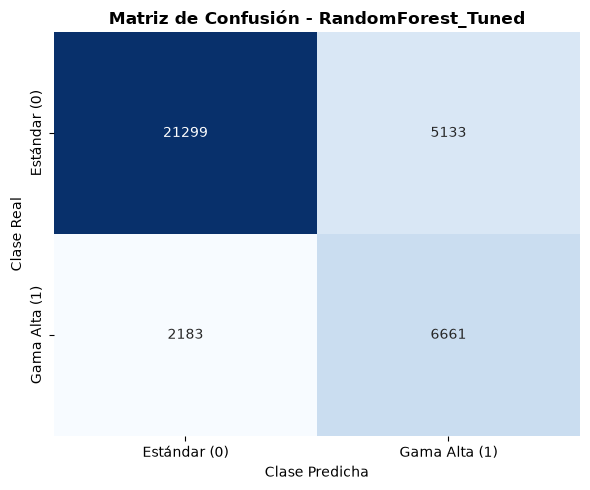

In [10]:
y_pred_winner = winner_pipeline.predict(X_test)
plot_and_save_confusion_matrix(
    y_test,
    y_pred_winner,
    output_path=BASE_DIR / "logs" / "matriz_confusion_ganador.png",
    title=f"Matriz de Confusión - {winner_name}"
)
plt.show()

## 9. Persistencia de Resultados y Parámetros en MongoDB


In [11]:
y_prob_winner = winner_pipeline.predict_proba(X_test) if hasattr(winner_pipeline, "predict_proba") else None

# Guardar resultados y métricas en MongoDB (colección 'resultados')
save_model_results_mongo(
    y_true=y_test,
    y_pred=y_pred_winner,
    y_prob=y_prob_winner,
    metrics=all_metrics[winner_name],
    model_name=winner_name,
    uri=MONGO_URI,
    db_name=MONGO_DB_NAME,
)

# Guardar hiperparámetros en MongoDB (colección 'parametros')
save_model_parameters_mongo(
    model_name=winner_name,
    best_params=grid_search.best_params_,
    uri=MONGO_URI,
    db_name=MONGO_DB_NAME,
)

# Serializar modelo en disco para la app Streamlit
save_model(winner_pipeline, BASE_DIR / "app" / "modelo_ganador.joblib")
print("Proceso de modelado y persistencia en MongoDB finalizado con éxito.")

2026-11-10 09:26:21,405 | INFO     | src.db_mongo | Resultados del modelo guardados en MongoDB [Colección 'resultados', _id: 6af30d6dc089d7125110e935]
2026-11-10 09:26:21,414 | INFO     | src.db_mongo | Parámetros del modelo guardados en MongoDB [Colección 'parametros', _id: 6af30d6dc089d7125110e939]
2026-11-10 09:26:21,485 | INFO     | src.models | Modelo serializado exitosamente en: /Users/fer/Library/CloudStorage/GoogleDrive-f.galera.05@gmail.com/My Drive/z - Licenciatura/3er cuatrimestre 2-2026/03 - Programacion avanzada/z - TP/taller_integrador/app/modelo_ganador.joblib


Proceso de modelado y persistencia en MongoDB finalizado con éxito.
